# Take-Home Exercise 3: Data Transformation & Regression
## Assignment Details
**Module Title:** Data Analytics  
**CRN:** 23631  
**Student:** Rory Patrick Sheridan - A00082654  
**Submission File:** `A00082654_Rory.pdf`  
**Dataset:**
Dataset A, a customer-level dataset for a service organisation that is deliberately not analysis-ready, recording age, income, monthly spend, visits, satisfaction, region, membership tier and whether the customer purchased a new service, `DatasetA_Customer.csv`.  
Dataset B, 36 monthly observations from January 2024 to December 2026 of electricity demand, average temperature, a synthetic industrial activity index, a time index and season, `DatasetB_Electricity.csv`.  
**Task:**
Identify and justify data-preparation choices, transform and represent variables appropriately, and apply feature engineering, principal component analysis and regression analysis.

Github Repository:  
https://github.com/Ri-Dearg/da-labs  
Github Notebook:  
https://github.com/Ri-Dearg/da-labs/blob/main/lab3_transform_regression.ipynb


### Libraries
Libraries used.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


### Dataset A: Customer Data


#### Data Overview

In [2]:
# Import Dataset A
df_a = pd.read_csv('customers.csv')
df_a.head()

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
0,C001,45.0,38182.0,758.81,9,7.9,Cork,Standard,Yes
1,C002,45.0,42762.0,553.10,3,4.4,Limerick,Basic,No
2,C003,46.0,33420.0,803.92,13,6.7,Dublin,Premium,Yes
3,C004,32.0,24445.0,404.97,4,5.9,Limerick,Basic,No
4,C005,50.0,78004.0,709.69,3,6.5,Limerick,Standard,Yes


In [3]:
# View data stats
df_a.describe()

,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score
count,70.000000,70.000000,72.000000,72.000000,71.000000
mean,38.728571,54695.457143,766.362778,6.513889,6.857746
std,12.566255,26904.020010,218.261558,2.906976,1.569592
min,19.000000,22000.000000,270.500000,2.000000,3.600000
25%,30.000000,36722.000000,588.937500,4.000000,5.800000
50%,39.000000,48205.000000,759.305000,6.000000,6.800000
75%,46.000000,72010.000000,910.507500,8.250000,7.900000
max,72.000000,146183.000000,1397.340000,14.000000,10.000000


In [4]:
# View categorical stats
df_a.describe(exclude='number')

,Customer_ID,Region,Membership,Purchased
count,72,71,71,72
unique,70,4,3,2
top,C017,Dublin,Basic,No
freq,2,30,34,40


#### Types

In [5]:
# Explore structure of the data
df_a.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         72 non-null     str    
 1   Age                 70 non-null     float64
 2   Annual_Income_EUR   70 non-null     float64
 3   Monthly_Spend_EUR   72 non-null     float64
 4   Visits_Per_Month    72 non-null     int64  
 5   Satisfaction_Score  71 non-null     float64
 6   Region              71 non-null     str    
 7   Membership          71 non-null     str    
 8   Purchased           72 non-null     str    
dtypes: float64(4), int64(1), str(4)
memory usage: 5.2 KB


#### Distributions

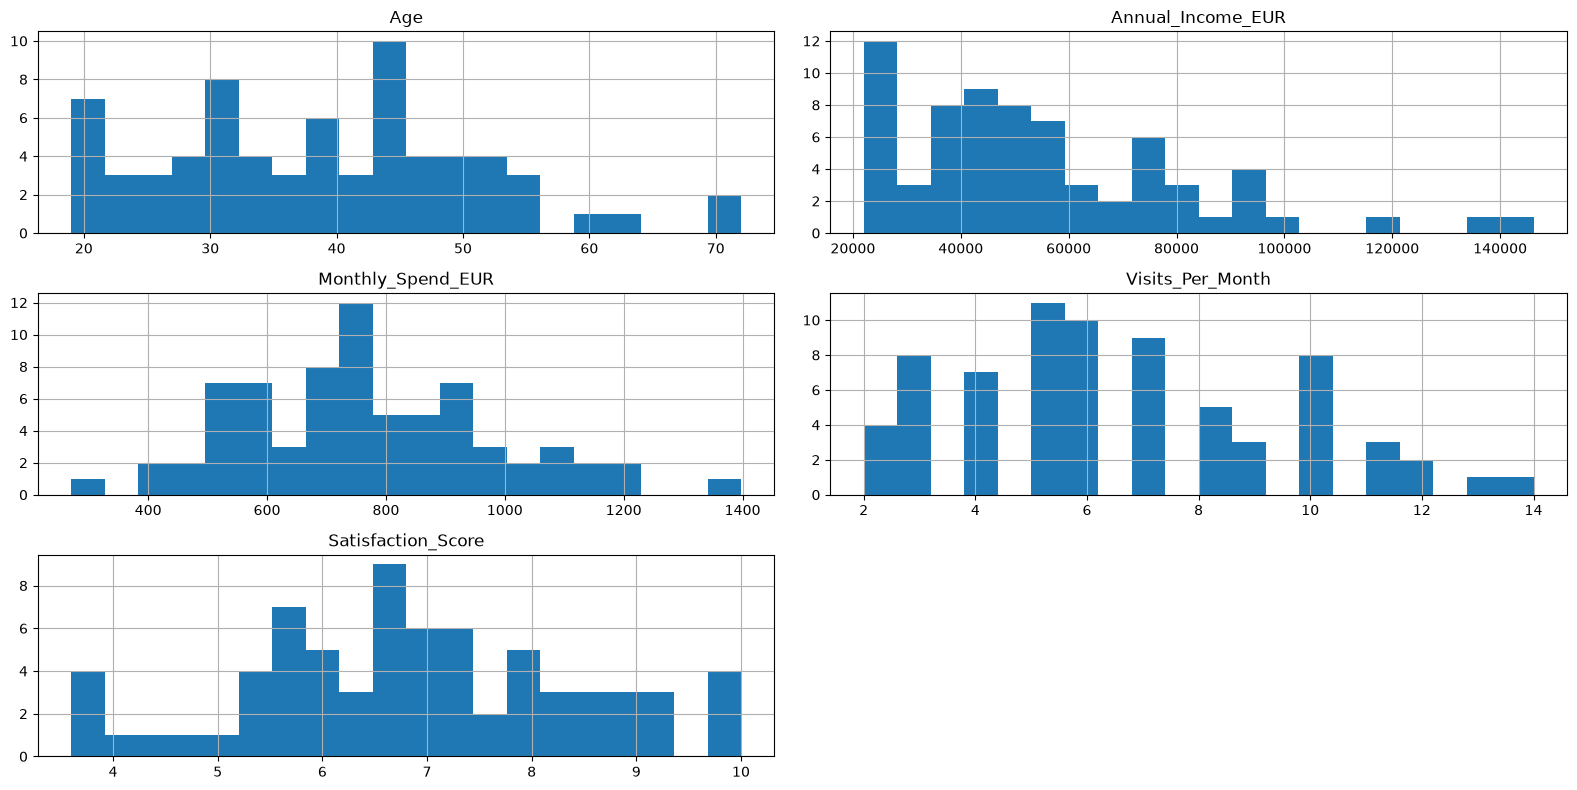

In [6]:
# Histograms for the distribution of each numeric variable
df_a.hist(figsize=(16, 8), bins=20)
plt.tight_layout()

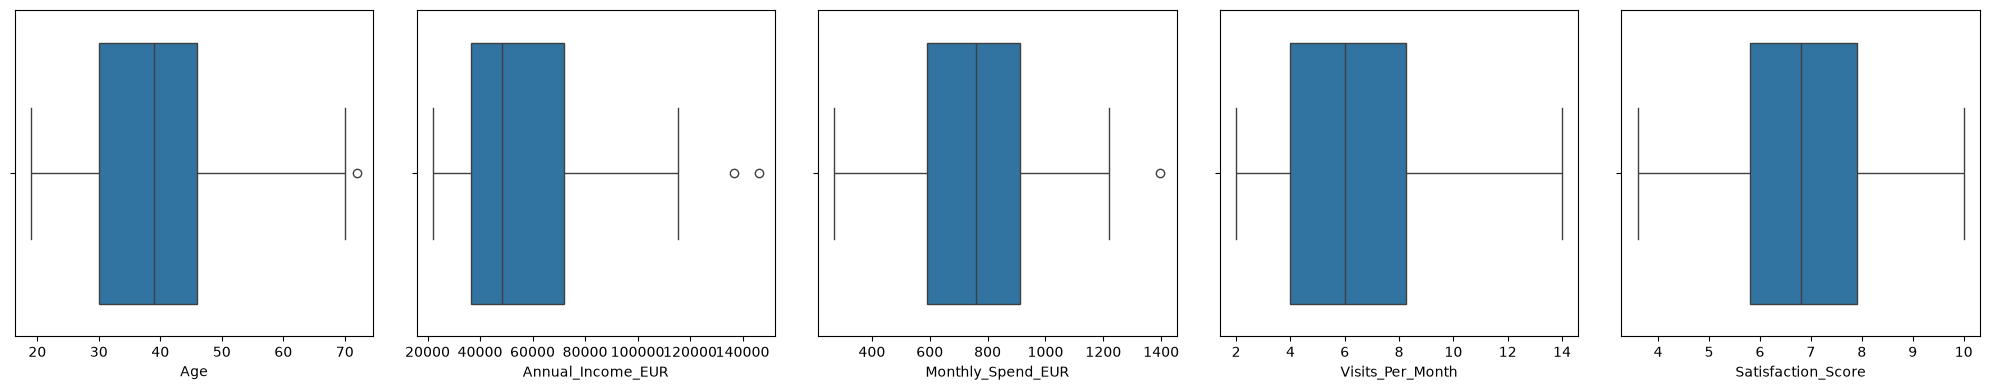

In [7]:
# Boxplots to check each numeric variable for outliers
cols = df_a.drop(columns='Customer_ID').select_dtypes('number')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes.flat, cols, strict=True):
    sns.boxplot(x=df_a[col], ax=ax)
plt.tight_layout()

In [8]:
# Skewness of each numeric variable
df_a.skew(numeric_only=True).round(2)

Age                   0.34
Annual_Income_EUR     1.19
Monthly_Spend_EUR     0.37
Visits_Per_Month      0.49
Satisfaction_Score   -0.07
dtype: float64

In [9]:
# Rows with a value beyond the 1.5 x IQR fences
num_a = df_a.select_dtypes('number')
q1_a, q3_a = num_a.quantile(0.25), num_a.quantile(0.75)
iqr_a = q3_a - q1_a
outside = (num_a < q1_a - 1.5 * iqr_a) | (num_a > q3_a + 1.5 * iqr_a)
df_a.loc[outside.any(axis=1), ['Customer_ID', *num_a.columns]]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score
8,C009,45.0,146183.0,1397.34,5,6.9
40,C041,72.0,37223.0,633.65,3,6.9
56,C057,36.0,136914.0,1103.29,5,6.4


#### Categorical Counts

In [10]:
# Counts of each categorical variable, including missing values
for col in ['Region', 'Membership', 'Purchased']:
    print(df_a[col].value_counts(dropna=False), '\n')

Region
Dublin      30
Limerick    16
Cork        14
Galway      11
NaN          1
Name: count, dtype: int64 

Membership
Basic       34
Standard    23
Premium     14
NaN          1
Name: count, dtype: int64 

Purchased
No     40
Yes    32
Name: count, dtype: int64 



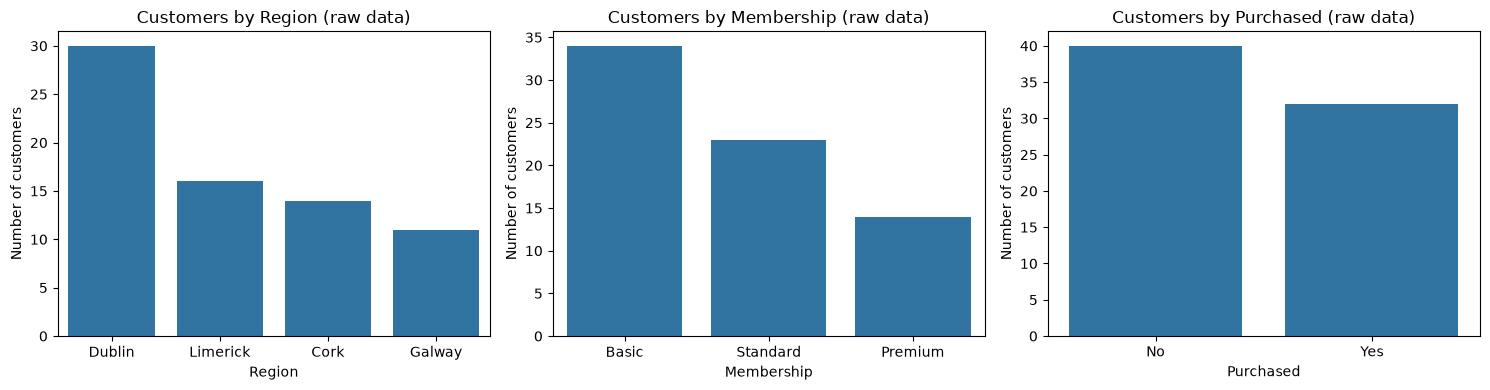

In [11]:
# Countplots of the categorical variables
orders = {
    'Region': df_a['Region'].value_counts().index,
    'Membership': ['Basic', 'Standard', 'Premium'],
    'Purchased': ['No', 'Yes'],
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, order) in zip(axes, orders.items(), strict=True):
    sns.countplot(data=df_a, x=col, order=order, ax=ax)
    ax.set(ylabel='Number of customers', title=f'Customers by {col} (raw data)')
plt.tight_layout()

## Question 1: Audit, Impute, and Transform Dataset A

### a) Audit the dataset before analysis. Report the number of rows, exact duplicate rows, and missing values by variable. Remove only exact duplicate records and report the resulting sample size.

**Rows:** The raw dataset has 72 rows and 9 columns.

**Exact duplicate rows:** 2. They are second copies of customers `C017` and `C044` with every value identical to the original rows.

**Missing values by variable:**

| Variable | Missing values | Customers |
|:--|--:|:--|
| `Customer_ID` | 0 | |
| `Age` | 2 | C007, C060 |
| `Annual_Income_EUR` | 2 | C019, C060 |
| `Monthly_Spend_EUR` | 0 | |
| `Visits_Per_Month` | 0 | |
| `Satisfaction_Score` | 1 | C030 |
| `Region` | 1 | C038 |
| `Membership` | 1 | C049 |
| `Purchased` | 0 | |
| **Total** | **7** | **6 customers** |

The duplicate rows have no missing values, so these counts are the same before and after they are removed. Customer C060 is missing both `Age` and `Annual_Income_EUR`.

I removed the two  duplicates. After removal every `Customer_ID` is unique. No other rows were removed.

**Resulting sample size:** n = 70 customers (72 - 2).

**Expected consequence:** Without the removal, C017 and C044 would each count twice, giving them double weight in every summary and test. All later analyses of Dataset A use the 70 unique customers.

In [12]:
df_a.shape

(72, 9)

In [13]:
# Check for duplicates
df_a.duplicated().sum()

np.int64(2)

In [14]:
# Show duplicates
df_a[df_a.duplicated(keep=False)]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
16,C017,45.0,48205.0,507.44,3,7.9,Cork,Basic,No
43,C044,35.0,22000.0,509.84,10,5.8,Dublin,Standard,Yes
70,C017,45.0,48205.0,507.44,3,7.9,Cork,Basic,No
71,C044,35.0,22000.0,509.84,10,5.8,Dublin,Standard,Yes


In [15]:
# Check for missing values by variable
df_a.isna().sum()

Customer_ID           0
Age                   2
Annual_Income_EUR     2
Monthly_Spend_EUR     0
Visits_Per_Month      0
Satisfaction_Score    1
Region                1
Membership            1
Purchased             0
dtype: int64

In [16]:
# Show the rows with missing values
df_a[df_a.isna().any(axis=1)]

,Customer_ID,Age,Annual_Income_EUR,Monthly_Spend_EUR,Visits_Per_Month,Satisfaction_Score,Region,Membership,Purchased
6,C007,NaN,23907.0,440.15,5,4.9,Dublin,Basic,No
18,C019,32.0,NaN,647.99,4,8.5,Dublin,Basic,Yes
29,C030,29.0,33932.0,522.00,8,NaN,Limerick,Basic,No
37,C038,23.0,33164.0,591.17,6,7.3,NaN,Standard,No
48,C049,53.0,25969.0,398.47,4,3.6,Galway,NaN,No
59,C060,NaN,NaN,693.82,2,5.4,Dublin,Basic,No


In [17]:
# Remove exact duplicates only, keeping the first copy
df_dedup = df_a.drop_duplicates()
df_dedup.shape

(70, 9)